# Does the growing season beat the winter rows?

In Sprint 1 I found that the yield label in our interim table sat on December and January windows, after harvest, and never on the June to September windows that actually grew the crop. I proposed tying each annual yield to its growing-season windows instead. This notebook checks whether that choice changes what a model can learn, using the Gold candidate.

The setup is kept small on purpose: 24 seasons (2 states x 2 crops x 6 years), six season-level features, fixed settings, no tuning. All the logic lives in `src/season_yield_baselines.py`; this notebook runs it and looks at the results.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path("..") / "src"))
import season_yield_baselines as syb

DATA_DIR = Path(os.environ.get("TERRAYIELD_DATA_DIR", "../data"))
OUT_DIR = Path("../results")

gold = syb.load_gold(DATA_DIR)
gold.attrs["raw_shape"]

(580, 81)

## One row per season

Every season gets the same six features, built twice:

- `growing`: windows starting June to September of that year
- `post_harvest`: windows starting in December of that year, which is roughly where the label used to sit

The features are average and peak NDVI, average SAVI, average daily maximum temperature, total precipitation and total solar radiation.

In [2]:
tables = {name: syb.season_table(gold, months) for name, months in syb.FEATURE_WINDOWS.items()}
print({name: sorted(t["windows"].unique().tolist()) for name, t in tables.items()}, "windows per season")
tables["growing"].round(3).head(8)

{'growing': [8, 9], 'post_harvest': [1, 2]} windows per season


,region,crop_type,year,ndvi_avg,ndvi_peak,savi_avg,tmax_avg,precip_total,radiation_total,windows,yield_t_ha
0,US-Illinois,corn,2020,0.605,0.813,0.429,31.838,295.3,703516,8,11.989
1,US-Illinois,corn,2021,0.637,0.823,0.466,32.650,453.9,669770,8,12.679
2,US-Illinois,corn,2022,0.661,0.839,0.486,33.275,337.0,724839,8,12.909
3,US-Illinois,corn,2023,0.637,0.828,0.463,32.362,369.9,734035,8,12.930
4,US-Illinois,corn,2024,0.653,0.819,0.481,32.737,293.5,744916,8,13.621
5,US-Illinois,corn,2025,0.662,0.845,0.492,32.775,245.1,706818,8,13.432
6,US-Illinois,soybean,2020,0.605,0.813,0.429,31.838,295.3,703516,8,4.035
7,US-Illinois,soybean,2021,0.637,0.823,0.466,32.650,453.9,669770,8,4.371


Corn sits around 11 to 13.6 t/ha and soybean around 3.6 to 4.4 t/ha. Any model that knows the crop already gets a high R², which is why I look at MAE in t/ha and at each crop on its own.

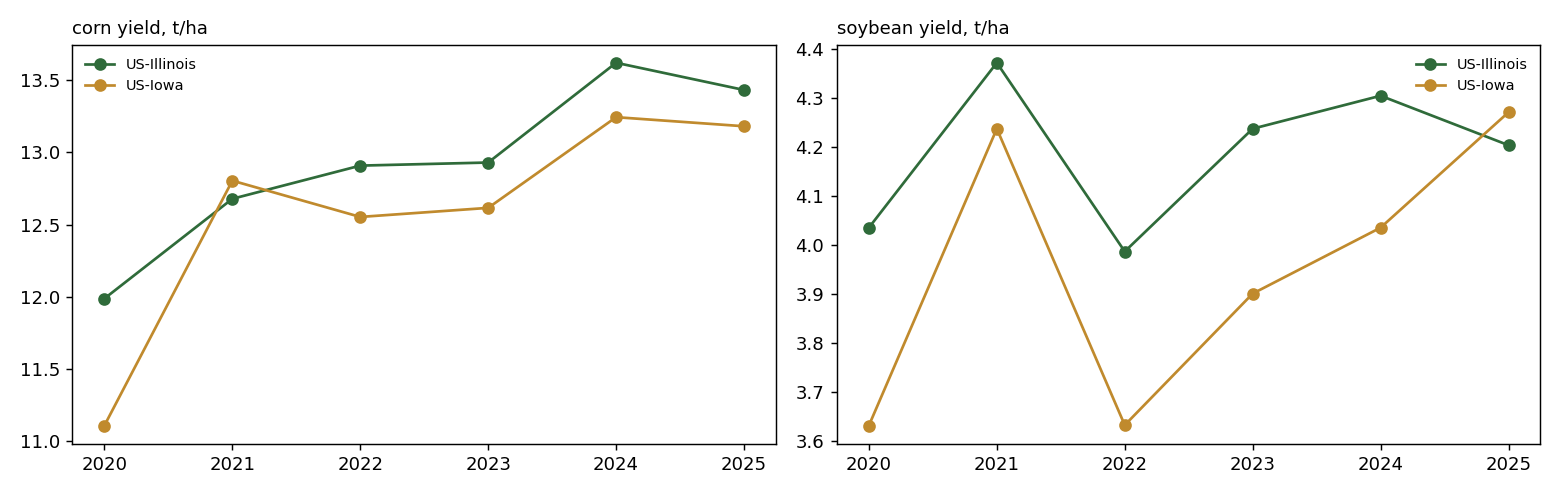

In [3]:
syb.plot_series(tables, OUT_DIR / "season_yields.png")
display(Image(filename=str(OUT_DIR / "season_yields.png")))

## Every model, both splits

Leave-one-year-out is what the project used. It lets 2025 help predict 2021, which is fine for a retrospective benchmark but is not how a forecast would be used. The expanding window only ever trains on earlier years and tests 2022 to 2025, so it is the stricter of the two.

In [4]:
pred = syb.run(tables)
metrics = syb.summarise(pred)
metrics

,scheme,model,features,mae,rmse,mape_pct,mae_corn,mae_soybean,n_predictions
0,expanding_window,previous_season,none,0.261,0.332,4.25,0.267,0.256,16
1,expanding_window,region_crop_mean,none,0.422,0.514,4.74,0.666,0.178,16
2,expanding_window,linear_trend,none,0.494,0.701,6.92,0.648,0.340,16
3,expanding_window,random_forest,growing,0.519,0.659,7.57,0.637,0.401,16
4,expanding_window,trend_plus_ridge,growing,0.521,0.701,7.58,0.642,0.400,16
5,expanding_window,random_forest,post_harvest,0.565,0.685,7.98,0.722,0.408,16
6,expanding_window,trend_plus_ridge,post_harvest,0.645,0.842,8.85,0.856,0.434,16
7,leave_one_year_out,trend_plus_ridge,growing,0.265,0.368,4.03,0.295,0.234,24
8,leave_one_year_out,linear_trend,none,0.327,0.441,4.42,0.441,0.213,24
9,leave_one_year_out,random_forest,post_harvest,0.365,0.513,4.71,0.520,0.209,24


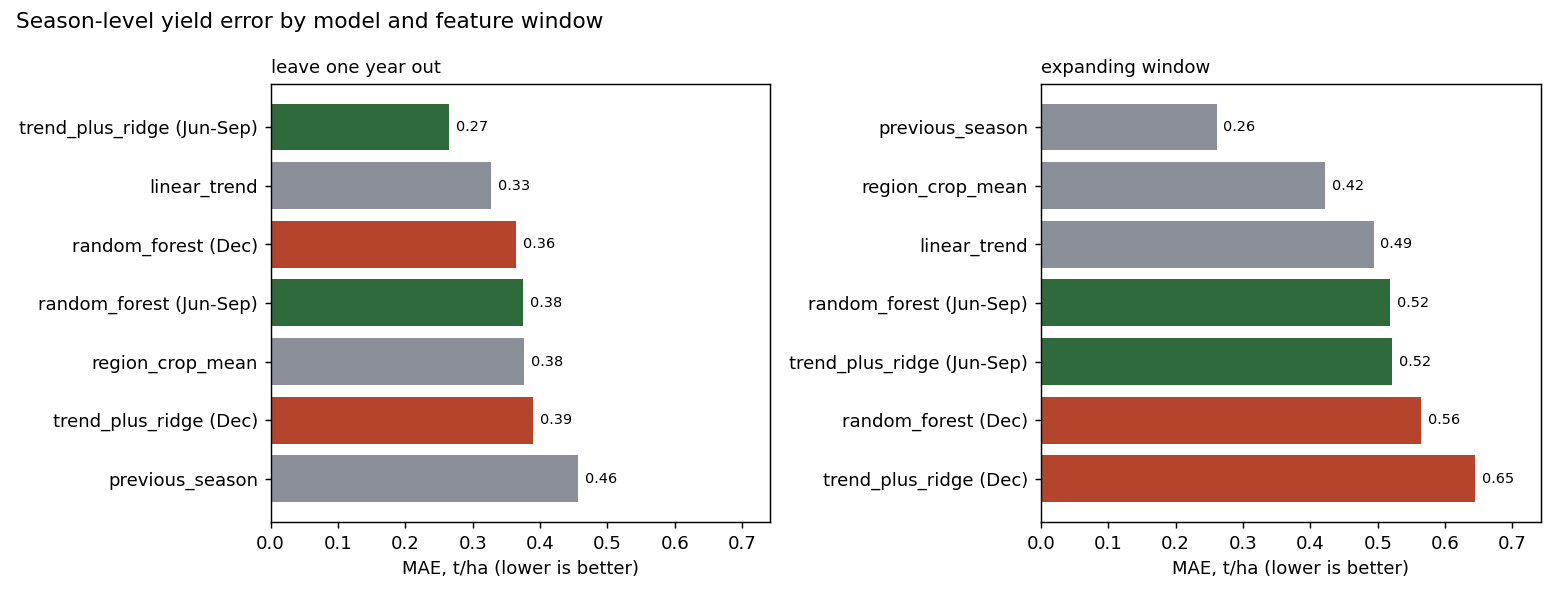

In [5]:
syb.plot_metrics(metrics, OUT_DIR / "season_experiment_mae.png")
display(Image(filename=str(OUT_DIR / "season_experiment_mae.png")))

## Is the ridge result just alpha = 1?

I fixed alpha at 1.0 before running anything. To make sure the comparison doesn't hinge on that, here is the same model at four values of alpha.

In [6]:
sens = syb.alpha_sensitivity(tables)
pd.DataFrame({(scheme, fs): vals for scheme, d in sens.items() for fs, vals in d.items()}).T

0.3    1.0    3.0   10.0
leave_one_year_out growing       0.297  0.265  0.244  0.252
                   post_harvest  0.432  0.390  0.366  0.341
expanding_window   growing       0.582  0.521  0.465  0.418
                   post_harvest  0.654  0.645  0.614  0.553

## Which features move with the yield gap?

Correlation of each feature with the relative gap between yield and its trend, over all 24 seasons.

In [7]:
pd.DataFrame(syb.signal_check(tables))

,growing,post_harvest
ndvi_avg,0.15,0.31
ndvi_peak,-0.22,0.38
savi_avg,0.15,0.31
tmax_avg,0.43,0.58
precip_total,0.19,-0.14
radiation_total,-0.11,0.03


## What I take from this

- **Retrospective (leave-one-year-out):** trend plus growing-season features gives the lowest error, 0.265 t/ha against 0.327 for the trend alone. The same model fed December features does worse than the plain trend (0.390).
- **Forecast-style (expanding window):** nothing beats last year's yield (0.261 t/ha). With two to five years of history, neither a trend line nor a feature model has enough to go on. This matches what the project team found in its own benchmark: simple baselines held up against every ML model.
- **Growing season vs December:** growing-season features do better in three of the four model and split pairs, and the ridge gap holds at every alpha from 0.3 to 10. The one exception is the random forest under leave-one-year-out, where December comes out 0.01 t/ha ahead.
- **A warning about 24 points:** the strongest single correlation with the yield gap is December temperature (0.58). There is no agronomic reason for winter temperature to explain the previous summer's harvest, so I read that as chance, and as a reason not to trust any single feature here.

**Caveats.** 24 seasons is a small sample. The satellite and weather features are regional and identical for corn and soybean, so they cannot explain why one crop did better than the other in the same state. Three 2022 yields in the Gold file differ from the earlier interim table (see `results/land_use_feature_checks.json`). Everything here is retrospective; nothing is an in-season forecast.

**Tuning note.** Alpha was fixed at 1.0 here. With alpha picked by an inner loop on the training years only, the same ridge model scores 0.294 under leave-one-year-out instead of 0.265, which is still ahead of the trend. That and the rest of the model work are in `crop_yield_model_development.ipynb`.